<a href="https://colab.research.google.com/github/Vincent-L0/A05-pca/blob/main/notebook.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

## PCA and Text Analysis

This assignment involves processing real e-mails, some of which are scams.

(Fair warning: Some of these scam e-mails have offensive content. If you start reading the e-mail text or the token data, you might read something offensive. If that's a problem, feel free to e-mail us, and we can talk about it and discuss how to proceed with alternative tasks.)

**Q1.**

**Tokens**: The individual words or symbols that create text data like emails. Natural Language Processing is primarily about analyzing the frequency and co-occurrence of tokens.

We aggregated all the emails into a single vector, and removed the punctuation and very common words (e.g. "the"). Run the below code chunk to open it, and use the Counter class to look at the most common words:

In [ ]:
import pickle

with open('/content/all_tokens.pickle', 'rb') as file:
    all_tokens = pickle.load(file)

from collections import Counter
token_count = Counter(all_tokens)
token_freq = token_count.most_common()

Plot a histogram of the occurrences of tokens.
What do you notice about the frequency of occurrence of different tokens? How does it look?

**Q2.**

Load `Phishing_clean.parquet`. This is the text from the e-mails broken into the most common 2,711 tokens and one-hot-encoded as features/covariates. So each row is an e-mail, the `Email Type` takes the value 1 if it's a scam and 0 otherwise, and every other column is a word or symbol that occurs in at least 15 e-mails.

1. Perform an 80/20 train-test split of the data.
2. Run a regression of $y$ on the one-hot-encoded emails. What is the $R^2$ on the test set? On the training set?
3. What words have the largest coefficients in absolute value and most strongly influence predictions?

**Q3.**

Take the matrix of one-hot-encoded tokens (the data, less the outcome variable, `Email Type`) and perform a principal components analysis decomposition with two components. Plot the first two principal components in a scatter plot, and hue the points by whether they are a phishing scam or not. Do you notice any patterns?

**Q4.**

Run a linear regression of $y$ on the first 2,610 principal components of $X$. What is the $R^2$ on the training and test sets?
How does this performance compare to the linear regression?

**Q5.**

Explain briefly in your own words what the advantage is in using the principal components to run this high-dimensional regression, rather than the original data.

---

## *Phase 1: Solution without AI

Complete all questions in the following cells without generative AI. Then commit and push the
notebook before beginning Phase 2.

**Declaration:** I completed this version without generative AI.

**Student(s):** [To be provided]

**Date:** [To be provided]

Total tokens: 276949
Unique tokens: 48691
15 most common: [('new', 1365), ('date', 1202), ('get', 1052), ('please', 1022), ('enron', 927), ('like', 923), ('2002', 869), ('would', 806), ('one', 798), ('message', 795), ('call', 740), ('free', 691), ('software', 680), ('dear', 651), ('know', 644)] 



,mean,median,mode,Q1,Q3
0,5.688,1.0,1,1.0,2.0


Tokens appearing once: 29404


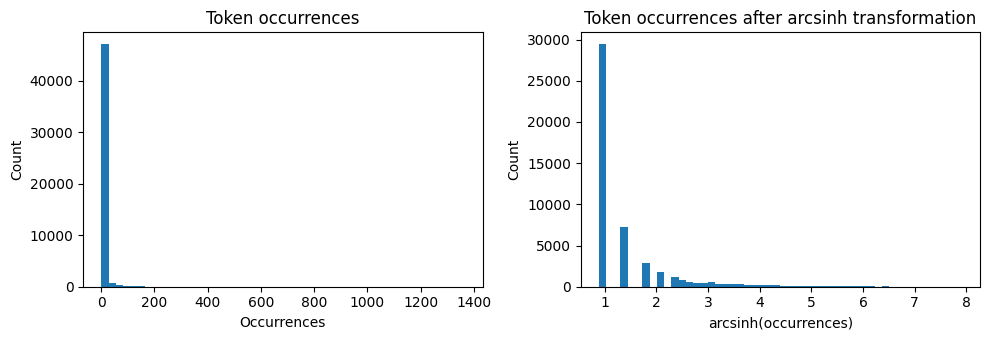


The histogram is very right-skewed. Of the 48691 unique tokens, 60.4% appear once and 87.2% appears 5 times or less; this results in 
almost every token being placed in the first few bars of the histogram. The most frequent token, 'new', appears 1365 times, creating a long, 
thin right tail. Even after applying an arcsinh transformation, the tokens are still pile on the left end and fall off to the right.

--------------------------------------------------------------------------

df.shape:
(18634, 2712) 

Email Type
0    11322
1     7312
Name: count, dtype: int64 



In [ ]:
import pickle
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd
import seaborn as sns
from collections import Counter
from IPython.display import display
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.decomposition import PCA

# Q1
with open("/content/all_tokens.pickle", "rb") as file:
    all_tokens = pickle.load(file)

token_count = Counter(all_tokens)
token_freq = token_count.most_common()

print("Total tokens:", len(all_tokens))
print("Unique tokens:", len(token_count))
print("15 most common:", token_freq[:15], "\n")

counts = pd.Series(dict(token_freq))

summary = pd.DataFrame({
    "mean": [counts.mean()],
    "median": [counts.median()],
    "mode": [counts.mode().iloc[0]],
    "Q1": [counts.quantile(0.25)],
    "Q3": [counts.quantile(0.75)],
})
display(summary.round(3))
print("Tokens appearing once:", sum(counts == 1))

counts_arcsinh = np.arcsinh(counts)

fig, axes = plt.subplots(1, 2, figsize=(10, 3.5))
counts.hist(bins=50, grid=False, ax=axes[0])
axes[0].set(title="Token occurrences", xlabel="Occurrences", ylabel="Count")
counts_arcsinh.hist(bins=50, grid=False, ax=axes[1])
axes[1].set(title="Token occurrences after arcsinh transformation",
            xlabel="arcsinh(occurrences)", ylabel="Count")
plt.tight_layout()
plt.show()

n_unique = len(counts)
share_once = round(100 * sum(counts == 1) / len(counts), 1)
share_five = round(100 * sum(counts <= 5) / len(counts), 1)
top_token = token_freq[0][0]
top_count = token_freq[0][1]

# What do you notice about the frequency of occurrence of different tokens? How does it look?

print(f"""
The histogram is very right-skewed. Of the {n_unique} unique tokens, {share_once}% appear once and {share_five}% appears 5 times or less; this results in
almost every token being placed in the first few bars of the histogram. The most frequent token, '{top_token}', appears {top_count} times, creating a long,
thin right tail. Even after applying an arcsinh transformation, the tokens are still pile on the left end and fall off to the right.
""")
print("--------------------------------------------------------------------------\n")
# Q2
df = pd.read_parquet("/content/Phishing_clean.parquet")

print("df.shape:")
print(df.shape, "\n")
print(df["Email Type"].value_counts(), "\n")

y = df["Email Type"]
X = df.drop(columns="Email Type")

# 1. 80/20 train-test split
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=100
)
# -
# 2. Regression of y on the one-hot-encoded tokens
sk_fit = LinearRegression().fit(X_train, y_train)

train_rsq = sk_fit.score(X_train, y_train)
test_rsq = sk_fit.score(X_test, y_test)
print("Train R-squared:", round(train_rsq, 4))
print("Test R-squared: ", round(test_rsq, 4))

# 3. Largest coefficients in absolute value
coefficients = pd.Series(sk_fit.coef_, index=X.columns)
# Sort from largest absolute value to smallest.
order = np.argsort(np.abs(coefficients.to_numpy()))[::-1]
top_words = coefficients.iloc[order[:20]]
display(top_words.round(4))

train_r2 = round(train_rsq, 3)
test_r2 = round(test_rsq, 3)
phishing_words = list(top_words[top_words > 0].index)
safe_words = list(top_words[top_words < 0].index)

# What is the  R2  on the test set? On the training set?
# What words have the largest coefficients in absolute value and most strongly influence predictions?

print(f"""
The R-squared value is {train_r2} on the training set and {test_r2} on the test set; this means that model fits the training emails better than new emails, so it is overfitting.
Words with the largest coefficients that suggest a phishing email: {phishing_words}
Words with the largest coefficients that suggest a safe email: {safe_words}
""")
print("--------------------------------------------------------------------------\n")
# Q3
pca = PCA(n_components=2).fit(X)
X_pca = pca.transform(X)
print("Variance explained:", pca.explained_variance_ratio_.round(3))

pc_df = pd.DataFrame(X_pca, columns=["PC1", "PC2"])
pc_df["Email Type"] = y.replace({0: "Safe", 1: "Phishing"}).to_numpy()

plt.figure(figsize=(7, 6))
sns.scatterplot(data=pc_df, x="PC1", y="PC2", hue="Email Type", alpha=0.35)
plt.title("First two principal components")
plt.show()

two_pc_share = round(100 * pca.explained_variance_ratio_.sum(), 1)

# Do you notice any patterns?

print(f"""
Phishing emails sit higher on PC2 than safe emails, but the two groups overlap heavily. The two PCA components explain only about 2% of the variance,
so they show some structure but can’t separate the classes cleanly. The separate clusters on the right are almost all safe emails
""")
print("--------------------------------------------------------------------------\n")

# Q4
pca_2610 = PCA(n_components=2610)
Z_train = pca_2610.fit_transform(X_train)
Z_test = pca_2610.transform(X_test)
print("Variance retained:", round(100 * pca_2610.explained_variance_ratio_.sum(), 2), "%")

pca_fit = LinearRegression().fit(Z_train, y_train)

pca_train_rsq = pca_fit.score(Z_train, y_train)
pca_test_rsq = pca_fit.score(Z_test, y_test)
print("Train R-squared:", round(pca_train_rsq, 4))
print("Test R-squared: ", round(pca_test_rsq, 4))

pca_train_r2 = round(pca_train_rsq, 3)
pca_test_r2 = round(pca_test_rsq, 3)
kept_share = round(100 * pca_2610.explained_variance_ratio_.sum(), 2)

# What is the  R2  on the training and test sets? How does this performance compare to the linear regression?

print(f"""
The R-squared value is {pca_train_r2} on the training set and {pca_test_r2} on the test set, compared to {train_r2} and {test_r2} for the linear regression model
on all 2,711 tokens. The performance between the two models are almost identical as {kept_share}% of the variance is retained.
""")
print("--------------------------------------------------------------------------\n")
# Q5

# Explain briefly in your own words what the advantage is in using the principal components to run this high-dimensional regression, rather than the original data.

print("""
The main advantage of using principal components for this high-dimensional regression over the original data for this data set is that many of the token columns are correlated
or redundant, which makes the regular regression coefficients unstable and overfits the model, while principal components carry the same information in uncorrelated directions
ranked by the variace each one explains; this means that the least important dimensions can be dropped, resulting in a smaller, more stable model that predicts just as well as
the linear regression model. This can be seen by how the test R^2 was practically unchanged in Q4.
""")

## *Phase 2: AI-assisted Revision
Keep Phase 1 frozen.

- **Phase 1 commit SHA ID:** [To be provided]
- **AI tool and model used:** [To be provided]

### *Prompts used

1. [Paste prompt]
2. [Paste follow-up prompt]

### *AI-proposed changes


[Paste the AI's concise numbered list verbatim.]

1. ...
2. ...

### *Evaluation of AI suggestions


| Change | Decision | Reason and verification |
|---|---|---|
| 1 | Accept / modify / reject | ... |
| 2 | Accept / modify / reject | ... |

### *AI-assisted solution in full
After the evaluation of AI suggestions, incorporate the accepted revisions into your Phase 1 solution and provide the final Phase 2 solution in full in the following cells.

In [ ]:
# Your Phase 2 solution to the problem goes here.


### *Reflection on AI assistance
In your own words without generative AI.

[In 150–300 words, describe the main improvements, AI mistakes or limitations, how the final solution was verified, and any remaining concerns.]